In [29]:
import pandas as pd
df = pd.read_csv('train.csv')
print(df.shape)
df.head()

(9800, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [30]:
df.info()
print(df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [31]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d/%m/%Y')
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
print(df['Year'].value_counts().sort_index())

Year
2015    1953
2016    2055
2017    2534
2018    3258
Name: count, dtype: int64


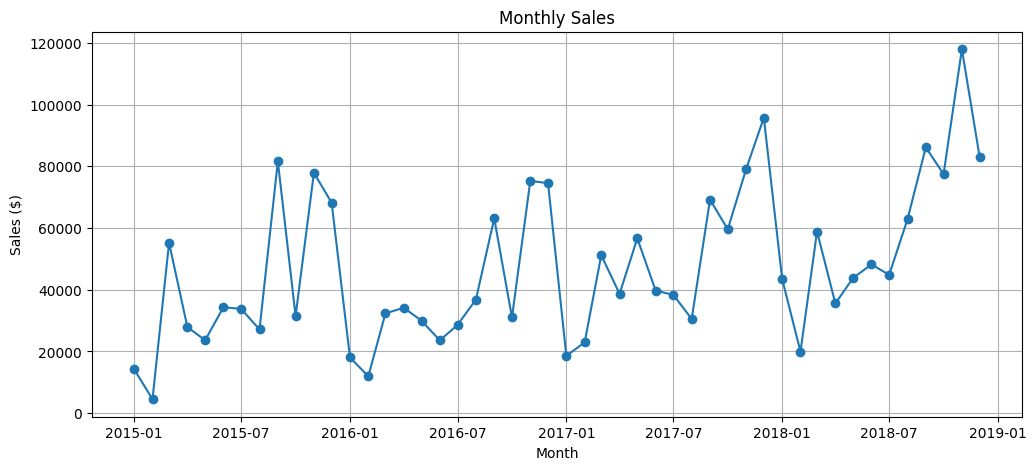

In [32]:
import matplotlib.pyplot as plt

monthly = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(12,5))
plt.plot(monthly.index, monthly.values, marker='o')
plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Sales ($)')
plt.grid(True)
plt.show()

### Observations: Monthly Sales
- Sales show an overall upward trend from 2015 to 2018.
- Clear seasonal peaks appear in November and December each year, likely due to holiday shopping.
- January and February are usually the weakest months.

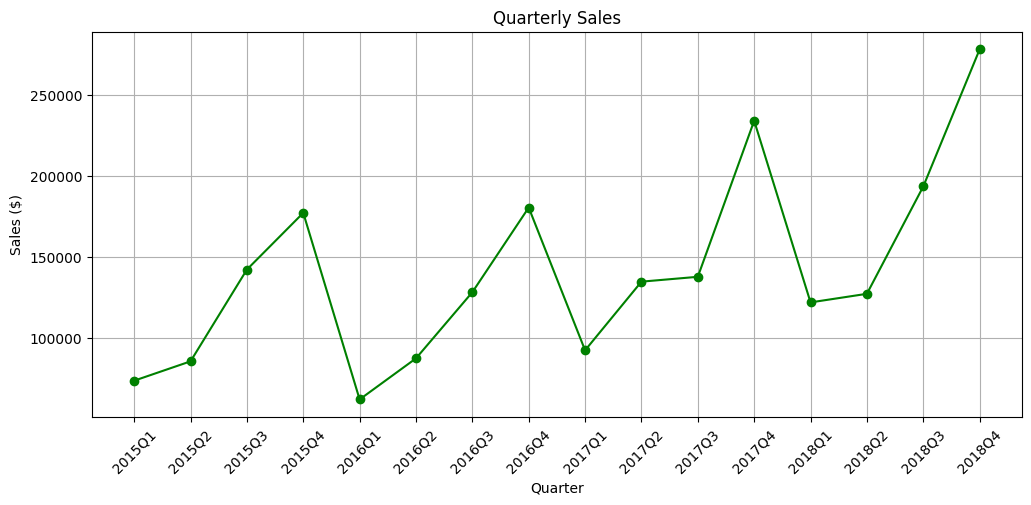

In [33]:
quarterly = df.groupby(df['Order Date'].dt.to_period('Q'))['Sales'].sum()
quarterly.index = quarterly.index.astype(str)

plt.figure(figsize=(12,5))
plt.plot(quarterly.index, quarterly.values, marker='o', color='green')
plt.title('Quarterly Sales')
plt.xlabel('Quarter')
plt.ylabel('Sales ($)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### Observations: Quarterly Sales
- Q4 is the strongest quarter every year (2015Q4, 2016Q4, 2017Q4).
- Q1 drops sharply after each Q4 peak, then sales recover gradually through Q2 and Q3.
- The peaks grow higher each year, confirming overall business growth.

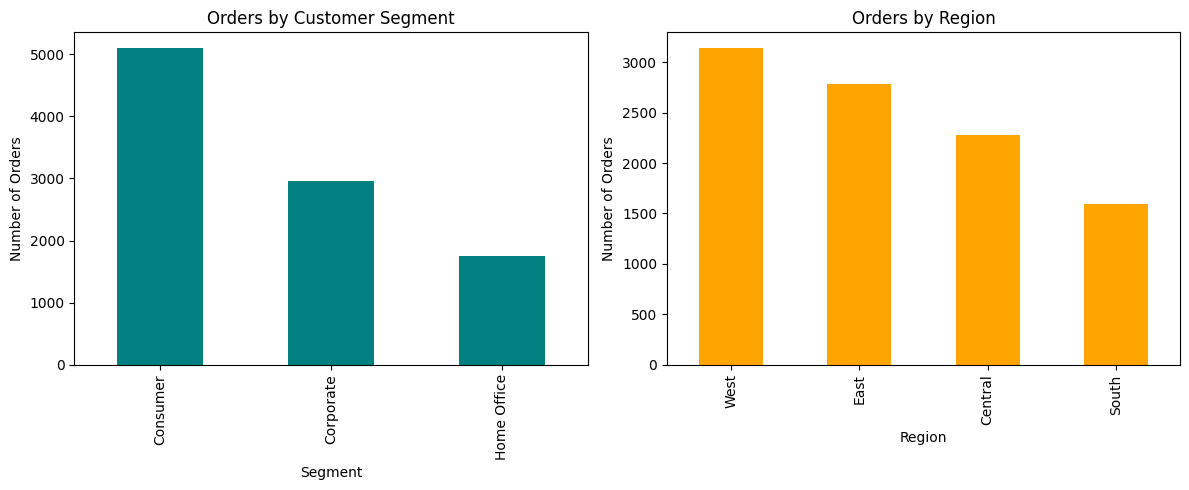

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))

df['Segment'].value_counts().plot(kind='bar', ax=ax[0], color='teal')
ax[0].set_title('Orders by Customer Segment')
ax[0].set_xlabel('Segment')
ax[0].set_ylabel('Number of Orders')

df['Region'].value_counts().plot(kind='bar', ax=ax[1], color='orange')
ax[1].set_title('Orders by Region')
ax[1].set_xlabel('Region')
ax[1].set_ylabel('Number of Orders')

plt.tight_layout()
plt.show()

### Observations: Customer Segments and Regions
- Consumer is the largest customer segment (over 4,000 orders), followed by Corporate, then Home Office.
- West and East regions generate the most orders, while South has the fewest.

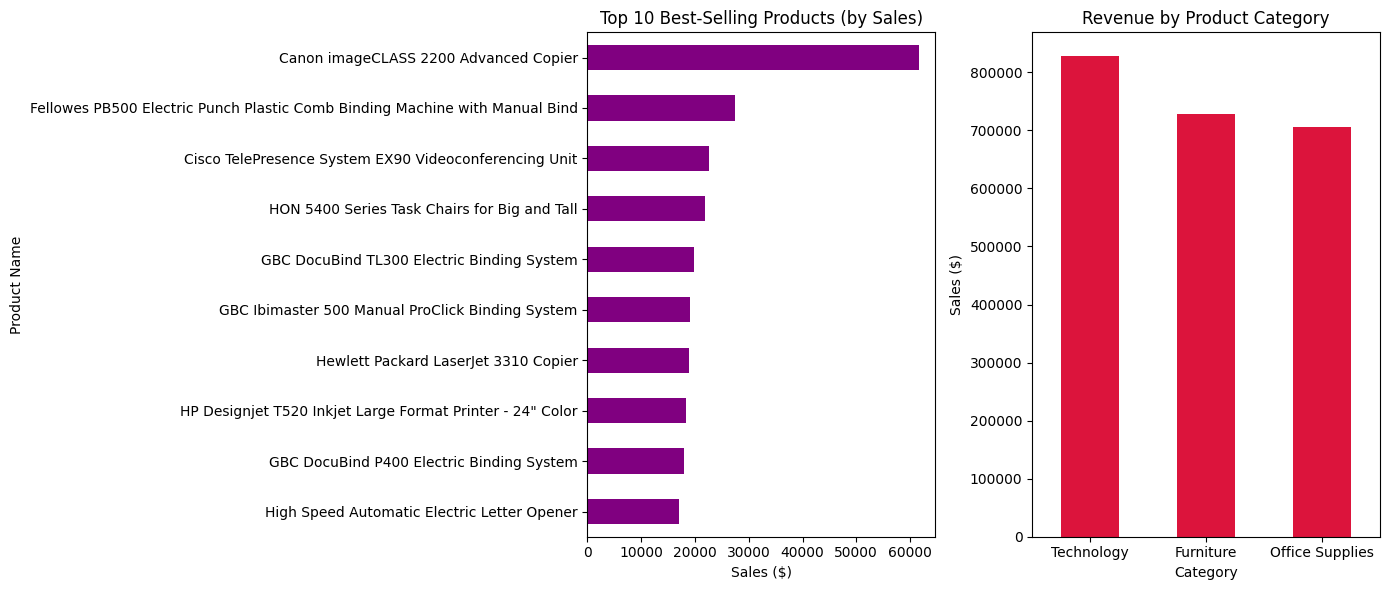

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(14,6))

top10 = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)
top10.sort_values().plot(kind='barh', ax=ax[0], color='purple')
ax[0].set_title('Top 10 Best-Selling Products (by Sales)')
ax[0].set_xlabel('Sales ($)')

cat = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
cat.plot(kind='bar', ax=ax[1], color='crimson')
ax[1].set_title('Revenue by Product Category')
ax[1].set_ylabel('Sales ($)')
ax[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Observations: Products and Categories
- Canon imageCLASS 2200 Advanced Copier is the top-selling product by a large margin.
- Most top-10 products are office machines and equipment (copiers, binding machines, printers).
- Technology generates the highest revenue among categories, followed closely by Furniture and Office Supplies.


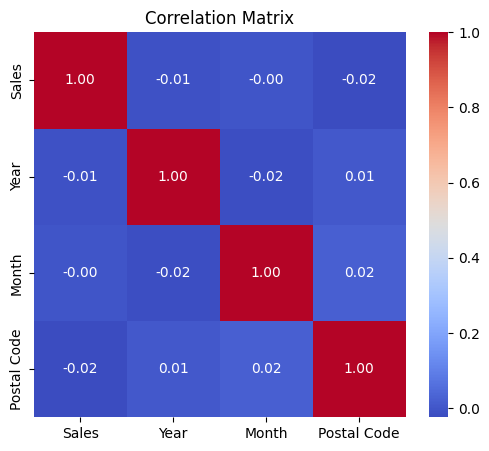

In [36]:
import seaborn as sns

num_df = df[['Sales', 'Year', 'Month', 'Postal Code']]
plt.figure(figsize=(6,5))
sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

### Observations: Correlation Matrix
- All correlations between Sales, Year, Month, and Postal Code are close to zero.
- This means there is no meaningful linear relationship between the order value and time or location code.
- Sales growth over the years comes from more orders (volume), not from higher order values.
- Postal Code is an identifier, not a true numeric feature, so its correlation is not meaningful.

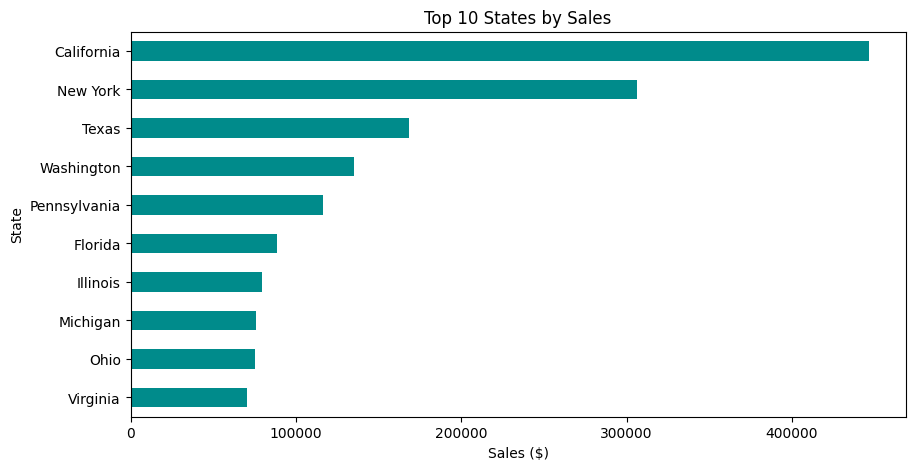

In [37]:
state_sales = df.groupby('State')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
state_sales.sort_values().plot(kind='barh', color='darkcyan')
plt.title('Top 10 States by Sales')
plt.xlabel('Sales ($)')
plt.show()

### Observations: Top 10 States by Sales
- California is the top state by a wide margin, with nearly double the sales of New York.
- California and New York together generate a large share of total revenue.
- From Illinois downward, the differences between states are small.
- This reveals a geographic concentration of sales that the other charts did not show.

## Conclusion: Business Recommendations
1. **Prepare for Q4 every year:** November and December are the strongest months, so stock up and run promotions before them. Use the slow months (January and February) for discounts to keep sales moving.
2. **Protect and grow the top states:** California and New York drive most revenue, so prioritize inventory and delivery quality there, and test marketing in the weaker regions like the South.
3. **Focus on top products and the Consumer segment:** Consumers place the most orders and Technology leads revenue, so feature best-selling products like copiers in campaigns.